# langfeat_teacher_check 诊断:dino.txt 指不准,是模型的问题还是量法的问题

**背景**:第一次检查(`report.ipynb`)里,dino.txt 按名字选的 patch 离物体中心的射线距离中位数是 0.63 m,没到 0.5 m 的判据。这里查原因。不训练任何东西。

**数据**:与第一次相同。EmbodiedScan 验证集 ScanNet,229 个场景 × 3 个种子,每个样本 8 张带位姿的图,场景内唯一的物体。

**每个物体在 12 种组合下各打一次分**(脚本 `jepa3d/tools/diagnose_teacher_grounding.py`)

| 维度 | 取值 |
|---|---|
| 文本特征 | `patch`:与 patch 对齐的后一半(官方用法);`cls`:与整图对齐的前一半(对照) |
| 提示模板 | `single`:"a photo of a {}";`ensemble`:8 个模板平均 |
| 打分 | `raw`:patch 与文本的余弦相似度;`centered`:减去该 patch 对词表里全部类别的平均相似度;`margin`:减去该 patch 上最强的其他类别 |

词表 = 训练集和验证集的全部类别名 + wall / floor 等结构类。`centered` 和 `margin` 问的是「这个 patch 最像哪个名字」,和官方分割用法一致;`raw` 问的是「这个名字最像哪个 patch」,是第一次检查的做法。

**指标**
- `到中心 (m)`:框中心到所选 patch 射线的距离,中位数。第一次检查用的指标,偏严。
- `穿过框`:所选 patch 的射线穿过物体的 3D 框。偏松,被前面的东西挡住也算中。
- `前5穿过框`:分数最高的 5 个 patch 里有一个穿过框。
- `AUC`:穿过框的 patch 分数高于不穿过框的 patch 的概率,0.5 是随机。不依赖只取一个 patch。

In [1]:
import json
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.width", 200)
%config InlineBackend.figure_formats = ["jpeg"]
plt.rcParams["savefig.dpi"] = 90

R = "../results/"
runs = {s: json.load(open(f"{R}diagnose_{s}.json")) for s in ("224x308", "448x616") if os.path.exists(f"{R}diagnose_{s}.json")}
RAW, BEST = "patch/single/raw", "patch/ensemble/centered"

def val(m, key, pct=True):
    v = m[key]
    if pct:
        return f'{100 * v["value"]:.1f}% [{100 * v["ci95"][0]:.1f}, {100 * v["ci95"][1]:.1f}]'
    return f'{v["value"]:.2f} [{v["ci95"][0]:.2f}, {v["ci95"][1]:.2f}]'

def variant_table(size, group="in_view"):
    m = runs[size]["metrics"]
    rows = []
    for v in runs[size]["variants"]:
        half, prompt, score = v.split("/")
        rows.append({"文本特征": half, "模板": prompt, "打分": score, "到中心 (m)": val(m, f"{group}/{v}/centre_m", False),
                     "0.5 m 内": val(m, f"{group}/{v}/centre_hit_acc"), "穿过框": val(m, f"{group}/{v}/in_box_acc"),
                     "前5穿过框": val(m, f"{group}/{v}/in_box5_acc"), "AUC": f'{m[f"{group}/{v}/auc_acc"]["value"]:.3f}'})
    return pd.DataFrame(rows)

m = runs["224x308"]["metrics"]
print("中心在视野内的物体:", m[f"in_view/{RAW}/centre_m"]["n"])
print("随机 patch 穿过框的比例:", f'{100 * m["in_view/anchor/box_frac_acc"]["value"]:.1f}%')
print("至少有一个 patch 穿过框的物体:", f'{100 * m["in_view/anchor/box_any_acc"]["value"]:.1f}%')
print("离中心最近的 patch 穿过框(框几何的自检):", f'{100 * m["in_view/anchor/centre_in_box_acc"]["value"]:.1f}%')

中心在视野内的物体: 4949
随机 patch 穿过框的比例: 5.8%
至少有一个 patch 穿过框的物体: 99.4%
离中心最近的 patch 穿过框(框几何的自检): 98.3%


## 1. 12 种组合(224×308,中心在视野内的物体)

方括号是按场景重采样的 95% 置信区间。第一行就是第一次检查的做法。

In [2]:
variant_table("224x308")

,文本特征,模板,打分,到中心 (m),0.5 m 内,穿过框,前5穿过框,AUC
0,patch,single,raw,"0.63 [0.58, 0.69]","42.8% [40.1, 45.6]","46.6% [44.3, 49.0]","59.0% [56.3, 61.6]",0.665
1,patch,single,centered,"0.46 [0.42, 0.50]","52.5% [49.8, 55.4]","60.8% [58.4, 63.0]","73.1% [70.9, 75.5]",0.792
2,patch,single,margin,"0.48 [0.45, 0.53]","51.2% [48.8, 53.8]","58.4% [56.0, 60.9]","70.2% [68.0, 72.6]",0.776
3,patch,ensemble,raw,"0.64 [0.57, 0.70]","42.1% [39.7, 44.4]","45.0% [42.9, 47.6]","57.7% [55.0, 60.5]",0.661
4,patch,ensemble,centered,"0.42 [0.39, 0.46]","54.8% [52.4, 57.4]","62.2% [60.1, 64.5]","74.3% [72.0, 76.7]",0.805
5,patch,ensemble,margin,"0.48 [0.44, 0.52]","51.4% [48.8, 53.8]","57.5% [55.0, 60.2]","71.0% [68.2, 73.4]",0.776
6,cls,single,raw,"1.27 [1.21, 1.34]","14.9% [13.0, 16.5]","14.7% [13.2, 15.9]","31.8% [29.6, 33.8]",0.627
7,cls,single,centered,"1.10 [1.04, 1.19]","19.4% [17.7, 21.3]","20.5% [18.6, 22.0]","35.5% [33.3, 37.5]",0.596
8,cls,single,margin,"1.16 [1.10, 1.24]","18.0% [16.1, 19.8]","18.1% [16.7, 19.6]","34.4% [32.3, 36.5]",0.583
9,cls,ensemble,raw,"1.25 [1.20, 1.32]","15.5% [14.0, 17.3]","15.4% [14.1, 16.9]","32.1% [29.7, 34.0]",0.627


## 2. 按物体大小和类别频率拆分

`raw` = 第一次检查的做法,`centered` = 这次最好的组合(patch / ensemble / centered)。物体大小取 3D 框最长边。

In [3]:
GROUPS = [("in_view", "全部(中心在视野内)"), ("in_view_size_lt0.5m", "最长边 < 0.5 m"), ("in_view_size_0.5-1m", "0.5–1 m"),
          ("in_view_size_gt1m", "> 1 m"), ("in_view_freq_200+", "训练集 200+ 次"), ("in_view_freq_20-199", "20–199 次"),
          ("in_view_freq_1-19", "1–19 次"), ("in_view_freq_unseen", "没出现过")]

def group_table(size):
    m = runs[size]["metrics"]
    rows = []
    for g, label in GROUPS:
        rows.append({"分组": label, "物体数": m[f"{g}/{RAW}/centre_m"]["n"],
                     "随机穿过框": f'{100 * m[f"{g}/anchor/box_frac_acc"]["value"]:.1f}%',
                     "raw 到中心 (m)": val(m, f"{g}/{RAW}/centre_m", False), "centered 到中心 (m)": val(m, f"{g}/{BEST}/centre_m", False),
                     "raw 穿过框": val(m, f"{g}/{RAW}/in_box_acc"), "centered 穿过框": val(m, f"{g}/{BEST}/in_box_acc"),
                     "centered 前5": val(m, f"{g}/{BEST}/in_box5_acc"), "centered AUC": f'{m[f"{g}/{BEST}/auc_acc"]["value"]:.3f}'})
    return pd.DataFrame(rows)

group_table("224x308")

,分组,物体数,随机穿过框,raw 到中心 (m),centered 到中心 (m),raw 穿过框,centered 穿过框,centered 前5,centered AUC
0,全部(中心在视野内),4949,5.8%,"0.63 [0.58, 0.69]","0.42 [0.39, 0.46]","46.6% [44.3, 49.0]","62.2% [60.1, 64.5]","74.3% [72.0, 76.7]",0.805
1,最长边 < 0.5 m,1703,0.8%,"1.07 [0.98, 1.16]","0.22 [0.19, 0.28]","19.1% [16.3, 22.2]","44.2% [40.4, 47.5]","60.1% [56.4, 64.1]",0.803
2,0.5–1 m,1260,4.2%,"0.46 [0.40, 0.58]","0.30 [0.28, 0.32]","47.8% [43.4, 52.3]","61.8% [58.1, 65.3]","71.1% [66.7, 75.2]",0.788
3,> 1 m,1986,11.2%,"0.55 [0.51, 0.58]","0.54 [0.52, 0.58]","69.5% [65.6, 72.7]","78.0% [74.9, 80.6]","88.6% [86.3, 90.7]",0.818
4,训练集 200+ 次,996,6.8%,"0.52 [0.48, 0.58]","0.43 [0.38, 0.46]","60.7% [56.0, 64.2]","75.8% [71.8, 79.6]","88.7% [85.4, 91.4]",0.853
5,20–199 次,3516,5.8%,"0.62 [0.56, 0.69]","0.40 [0.37, 0.45]","45.5% [42.9, 48.1]","61.3% [58.7, 64.0]","73.1% [70.2, 75.6]",0.798
6,1–19 次,408,4.0%,"1.16 [0.96, 1.29]","0.62 [0.48, 0.79]","24.8% [17.0, 33.2]","41.2% [34.5, 48.6]","53.9% [47.7, 61.5]",0.758
7,没出现过,29,1.5%,"2.24 [1.36, 2.74]","1.55 [1.22, 2.05]","3.4% [0.0, 10.4]","6.9% [0.0, 14.8]","20.7% [4.9, 44.5]",0.666


## 3. 输入分辨率 448×616(同样的拆分)

In [4]:
group_table("448x616") if "448x616" in runs else print("没有 448x616 的结果")

,分组,物体数,随机穿过框,raw 到中心 (m),centered 到中心 (m),raw 穿过框,centered 穿过框,centered 前5,centered AUC
0,全部(中心在视野内),4949,5.8%,"0.60 [0.56, 0.66]","0.43 [0.40, 0.46]","51.3% [49.2, 53.6]","65.6% [63.4, 67.8]","74.5% [72.2, 76.9]",0.793
1,最长边 < 0.5 m,1703,0.8%,"1.06 [0.91, 1.15]","0.18 [0.17, 0.21]","26.5% [23.2, 29.9]","51.4% [47.6, 55.4]","63.4% [59.7, 66.9]",0.793
2,0.5–1 m,1260,4.2%,"0.39 [0.34, 0.51]","0.30 [0.28, 0.33]","50.8% [46.0, 55.5]","62.9% [58.8, 66.7]","71.0% [66.9, 75.1]",0.774
3,> 1 m,1986,11.2%,"0.56 [0.53, 0.60]","0.56 [0.54, 0.59]","72.9% [70.0, 75.8]","79.5% [76.3, 82.1]","86.3% [83.5, 88.7]",0.805
4,训练集 200+ 次,996,6.8%,"0.50 [0.46, 0.54]","0.45 [0.41, 0.48]","67.3% [62.9, 71.5]","78.3% [74.9, 81.9]","87.0% [84.3, 90.3]",0.839
5,20–199 次,3516,5.8%,"0.61 [0.56, 0.66]","0.41 [0.37, 0.44]","50.0% [47.2, 52.4]","64.7% [62.1, 67.1]","73.3% [70.3, 75.9]",0.787
6,1–19 次,408,4.0%,"1.09 [0.90, 1.25]","0.59 [0.44, 0.83]","27.0% [19.7, 34.8]","46.3% [39.5, 55.1]","58.3% [51.2, 66.3]",0.741
7,没出现过,29,1.5%,"1.94 [1.36, 2.30]","2.02 [1.22, 2.40]","3.4% [0.0, 10.3]","6.9% [0.0, 15.4]","20.7% [3.4, 44.9]",0.650


## 4. 按类别(224×308,centered,中心在视野内,至少 30 个物体的类别)

`画面占比` = 该物体的框占全部 patch 的平均比例,即随机 patch 穿过框的概率。

In [5]:
rows = [json.loads(line) for line in open(f"{R}diagnose_224x308.objects.jsonl")]
df = pd.DataFrame([{"category": r["category"], "in_view": r["in_view"], "longest_m": r["longest_m"], "box_frac": r["box_frac"],
                    "train_count": r["train_count"], "raw": r[RAW]["in_box"], "centered": r[BEST]["in_box"],
                    "centre_m": r[BEST]["centre_m"], "auc": r[BEST]["auc"]} for r in rows])
view = df[df.in_view]
cats = view.groupby("category").agg(物体数=("centered", "size"), raw穿过框=("raw", "mean"), centered穿过框=("centered", "mean"),
                                    到中心中位数_m=("centre_m", "median"), AUC=("auc", "mean"), 最长边_m=("longest_m", "median"),
                                    画面占比=("box_frac", "mean"), 训练集次数=("train_count", "first"))
cats = cats[cats.物体数 >= 30].sort_values("centered穿过框")
print(len(cats), "个类别")
pd.concat([cats.head(12), cats.tail(12)]).round(2)

50 个类别


,物体数,raw穿过框,centered穿过框,到中心中位数_m,AUC,最长边_m,画面占比,训练集次数
category,,,,,,,,
picture,85,0.01,0.07,1.22,0.56,0.53,0.02,138
switch,106,0.00,0.10,1.24,0.71,0.14,0.00,107
stand,79,0.08,0.18,1.87,0.61,0.77,0.04,108
paper,82,0.09,0.21,1.00,0.74,0.28,0.01,153
bar,38,0.00,0.21,1.13,0.85,0.66,0.01,16
clothes,49,0.27,0.22,0.99,0.75,0.72,0.03,67
socket,137,0.09,0.23,1.12,0.65,0.13,0.02,190
cup,44,0.05,0.30,0.15,0.87,0.16,0.00,101
bottle,71,0.00,0.41,0.17,0.80,0.21,0.00,115


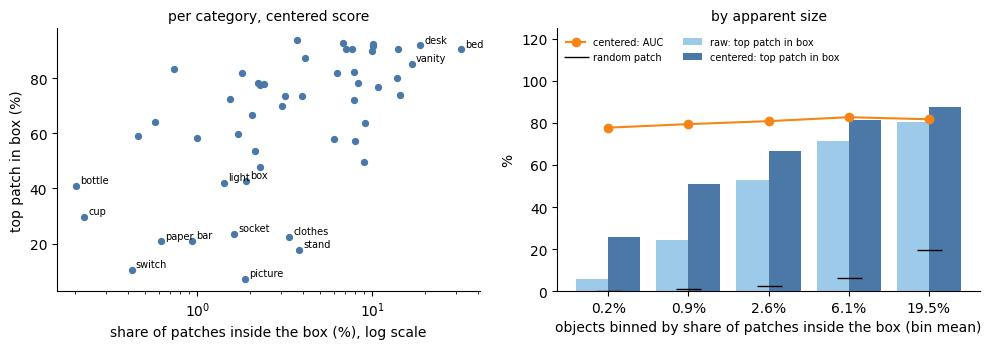

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
ax = axes[0]
ax.scatter(100 * cats.画面占比, 100 * cats.centered穿过框, s=18, color="#4c78a8")
for name, row in cats.iterrows():
    if row.centered穿过框 < 0.45 or row.画面占比 > 0.15:
        ax.annotate(name, (100 * row.画面占比, 100 * row.centered穿过框), fontsize=7, xytext=(3, 2), textcoords="offset points")
ax.set_xscale("log"); ax.set_xlabel("share of patches inside the box (%), log scale"); ax.set_ylabel("top patch in box (%)")
ax.set_title("per category, centered score", fontsize=10)
ax = axes[1]
bins = pd.qcut(view.box_frac, 5)
by = view.groupby(bins, observed=True).agg(raw=("raw", "mean"), centered=("centered", "mean"), auc=("auc", "mean"), frac=("box_frac", "mean"))
x = np.arange(len(by))
ax.bar(x - 0.2, 100 * by.raw, 0.4, color="#9ecae9", label="raw: top patch in box")
ax.bar(x + 0.2, 100 * by.centered, 0.4, color="#4c78a8", label="centered: top patch in box")
ax.plot(x, 100 * by.auc, "o-", color="#f58518", label="centered: AUC")
ax.plot(x, 100 * by.frac, "k_", markersize=18, label="random patch")
ax.set_xticks(x); ax.set_xticklabels([f"{100 * f:.1f}%" for f in by.frac]); ax.set_xlabel("objects binned by share of patches inside the box (bin mean)")
ax.set_ylabel("%"); ax.set_ylim(0, 125); ax.set_title("by apparent size", fontsize=10); ax.legend(frameon=False, fontsize=7, ncol=2, loc="upper left")
for a in axes:
    a.spines[["top", "right"]].set_visible(False)
plt.tight_layout(); plt.show()

## 5. 例子

每行一个物体,取能看到它的框最多的那个视角。左:图和框内 patch 的轮廓(绿);中:`raw` 的相似度图;右:`patch / ensemble / margin` 的分数图(存热图时只存了这两种,`centered` 没存)。白色星号是 8 个视角里分数最高的 patch,不在这个视角时标题里写它在哪个视角。颜色范围按该物体 8 个视角的最小最大值。

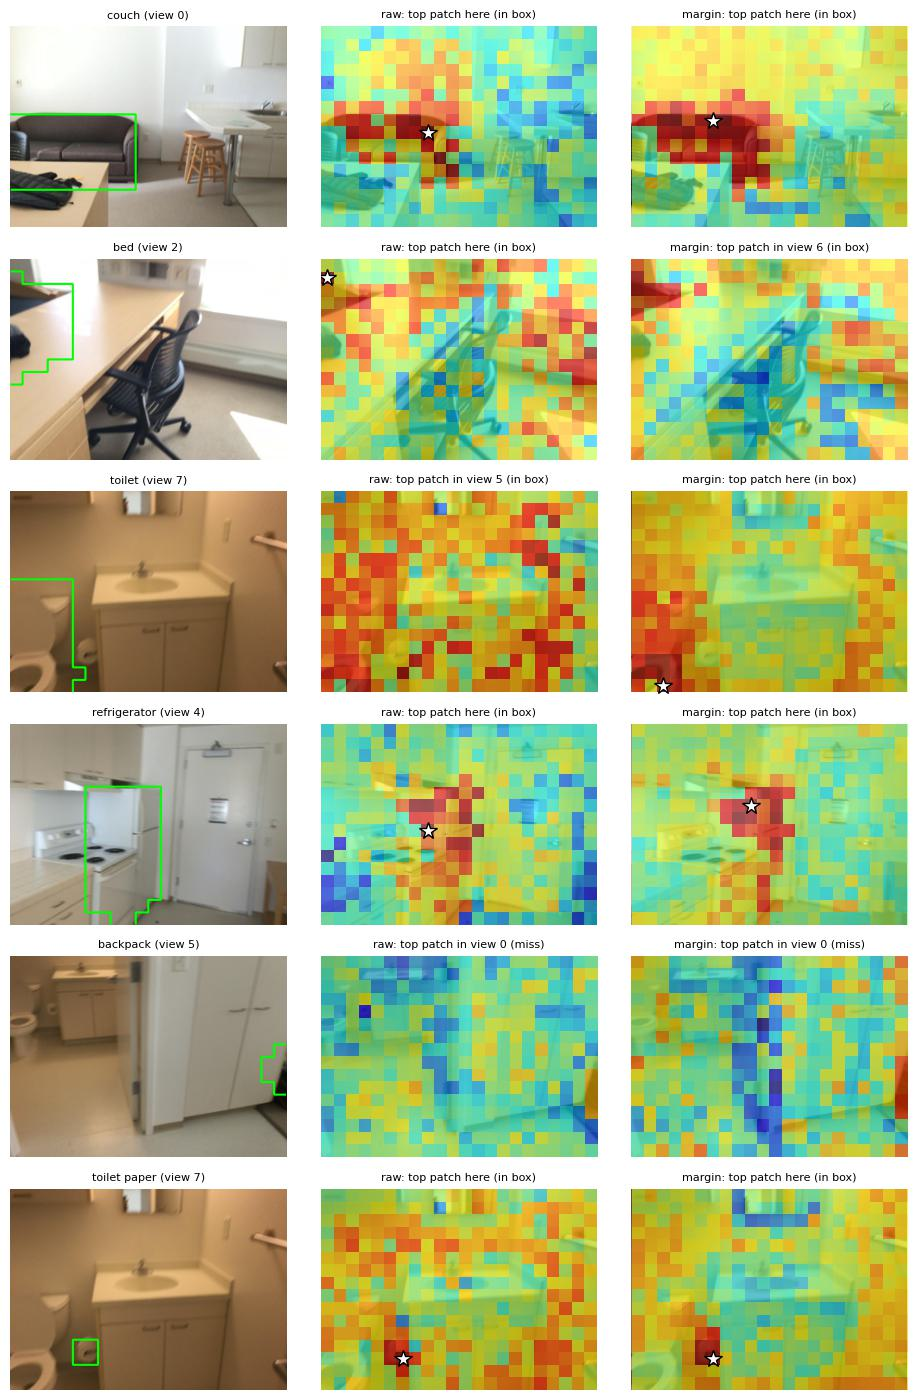

In [7]:
z = np.load(f"{R}diagnose_224x308.examples.npz")
H, W, P = 16, 22, 14

def panel(step, names):
    cats_ = list(z[f"{step}:categories"]); imgs = z[f"{step}:images"]
    box = z[f"{step}:in_box"].reshape(len(cats_), 8, H, W)
    fig, axes = plt.subplots(len(names), 3, figsize=(9.5, 2.35 * len(names)))
    for r, name in enumerate(names):
        o = cats_.index(name); v = box[o].sum((1, 2)).argmax()
        for c, (key, title) in enumerate(((None, ""), ("patch/single/raw", "raw"), ("patch/ensemble/margin", "margin"))):
            ax = axes[r, c]; ax.imshow(imgs[v]); ax.axis("off")
            if key is None:
                if box[o, v].any():
                    ax.contour(np.kron(box[o, v], np.ones((P, P))), levels=[0.5], colors="lime", linewidths=1.5)
                ax.set_title(f"{name} (view {v})", fontsize=8)
                continue
            s = z[f"{step}:{key}"][o].astype(np.float32).reshape(8, H, W)
            ax.imshow(s[v], extent=(0, W * P, H * P, 0), alpha=0.6, cmap="jet", interpolation="nearest", vmin=s.min(), vmax=s.max())
            top = s.reshape(-1).argmax(); tv, ty, tx = np.unravel_index(top, (8, H, W))
            hit = "in box" if box[o].reshape(-1)[top] else "miss"
            ax.set_title(f"{title}: top patch " + ("here" if tv == v else f"in view {tv}") + f" ({hit})", fontsize=8)
            if tv == v:
                ax.plot((tx + 0.5) * P, (ty + 0.5) * P, "w*", markersize=13, markeredgecolor="k")
    plt.tight_layout(); plt.show()

panel(114, ["couch", "bed", "toilet", "refrigerator", "backpack", "toilet paper"])

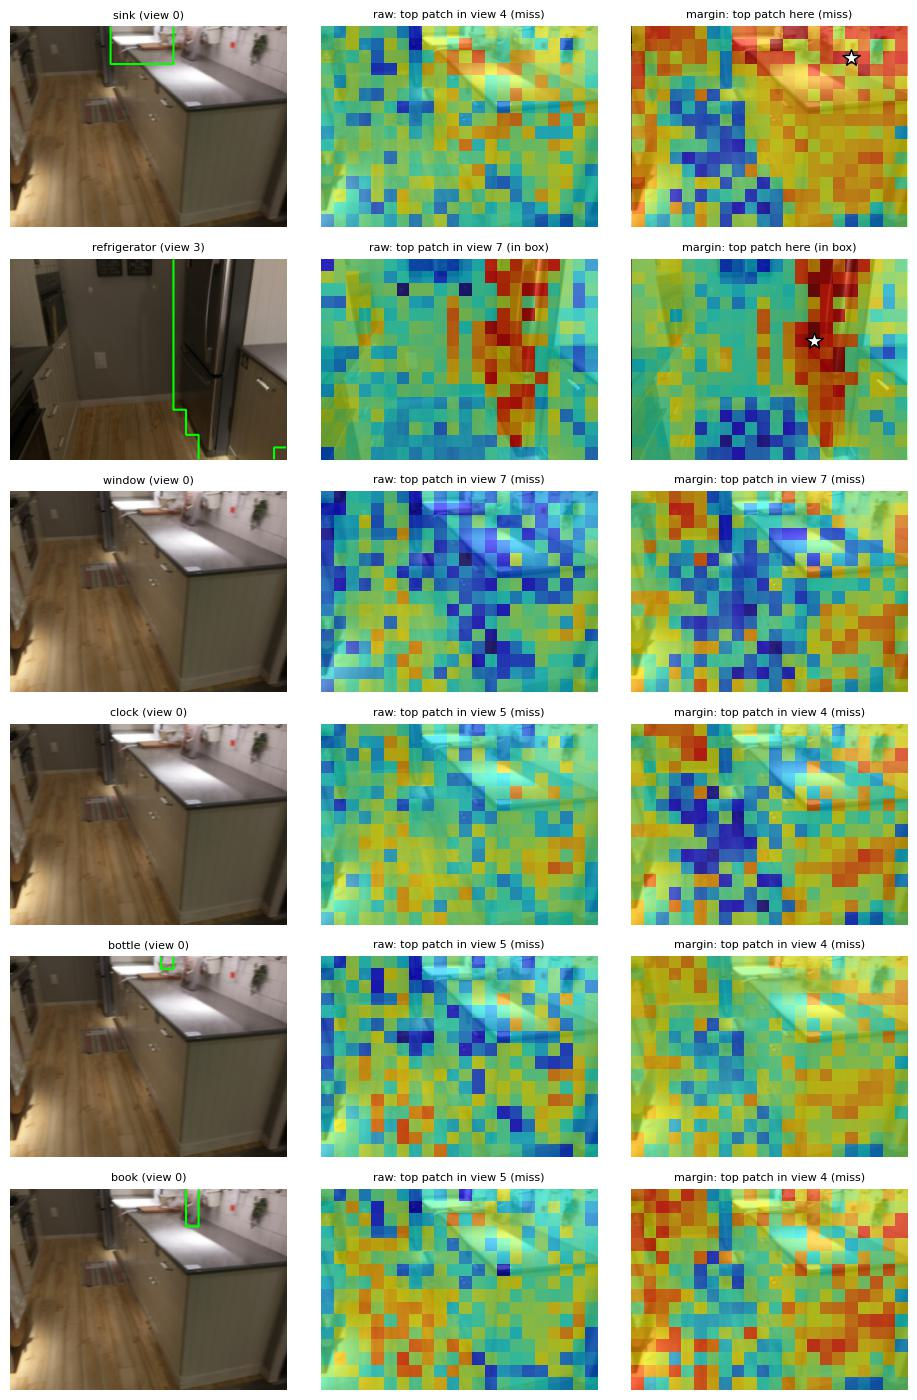

In [8]:
panel(171, ["sink", "refrigerator", "window", "clock", "bottle", "book"])

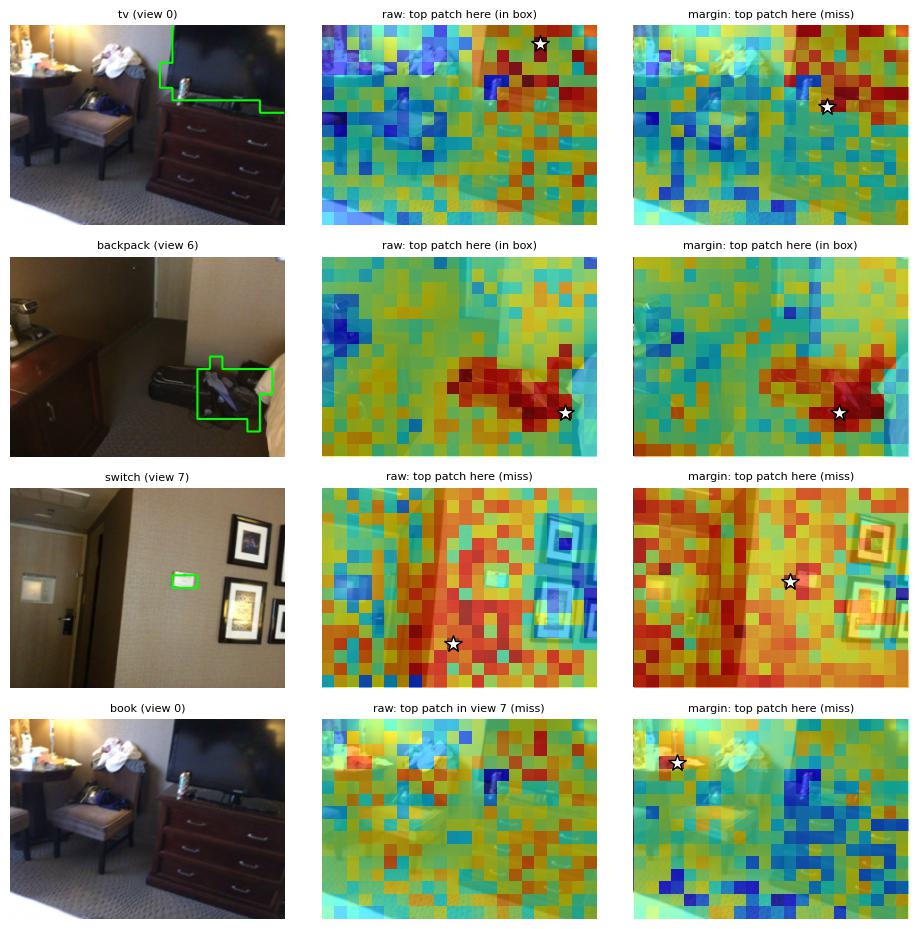

In [9]:
panel(0, ["tv", "backpack", "switch", "book"])

## 6. 结论

1. **第一次的 0.63 m 主要是打分方式造成的,不是 dino.txt 不行。** 把原始相似度换成 `centered`(减去每个 patch 对全部类别的平均相似度)后,224×308 下到中心的距离从 0.63 m 降到 0.43 m,过了 0.5 m 的判据;射线穿过框的比例从 46.6% 升到 62.2%(随机 5.8%),AUC 从 0.67 升到 0.81。原因是有些 patch 对任何文本的相似度都偏高,取 argmax 时会被它们抢走。
2. **文本特征没有取错。** 换成与整图对齐的那一半,穿过框只有 15–22%。
3. **模板平均作用很小**(0.46 → 0.43 m,区间重叠)。`margin` 比 `centered` 略差。
4. **「到中心 0.5 m」对大物体确实偏严。** 最长边 > 1 m 的物体,78% 的射线穿过框,但到中心的中位数仍是 0.55 m。
5. **剩下的失败集中在小物体。** 最长边 < 0.5 m 的物体只有 44% 穿过框,而它们的 AUC(0.80)和大物体(0.82)几乎一样:信号在,但物体在图里平均只占 0.8% 的 patch,取单个最高分 patch 容易错过。开关、插座、纸最差。挂画(picture)是另一种情况,AUC 只有 0.56,是认不出。
6. **分辨率对小物体有一点帮助。** 448×616 下小物体穿过框 44% → 51%,整体 62% → 66%,到中心的距离不变。
7. **类别频率的影响不能只用物体大小解释。** 在同一个大小档里,训练集 1–19 次的类别仍明显差于 200+ 次的(< 0.5 m:31% 对 71%;0.5–1 m:30% 对 83%)。dino.txt 没用过我们的标注,所以这更可能反映这些名字本身少见或有歧义,这一点没有进一步验证。

**对路线 1 的含义**:老师够用,但要蒸馏的应该是 `centered` 之后的分数(或在学生侧做同样的去均值),而不是原始相似度;评估时不要只看到中心的距离。小物体和冷门类别是老师的上限所在,蒸馏不会超过它。

## 7. 局限

- 「穿过框」偏松:被前面物体挡住的也算中。它和「到中心 0.5 m 内」(54.8%)一严一松,真实水平在两者之间。没有用深度图做遮挡判断。
- `centered` 和 `margin` 依赖词表(这里约 260 个类别名)。换一个词表数值会变,没有试。
- 例子里 EmbodiedScan 的框和类别名有噪声(例如第 5 节里标成 desk 的框),没有统计比例。
- 物体只取场景内唯一的类别。只跑了 dino.txt 一个老师。
- 热图只存了 `raw` 和 `margin`,没有存最好的 `centered`。
